# Constraint-Aware University Exam Timetabling Using a Genetic Algorithm

**Paste this title in the shared sheet.**  
Soft Computing course project. Runs on a laptop CPU in VS Code / Jupyter. No GPU.

| Field | What to write |
| --- | --- |
| Tentative Project Title | Constraint-Aware University Exam Timetabling Using a Genetic Algorithm |
| Problem | Pack exams so no student has two papers at once and rooms are not overbooked |
| Technique | Genetic Algorithm (evolutionary computing) |
| Inputs | 10 courses, 48 students, 3 rooms, 6 slots |
| Outputs | A clash-minimized timetable |
| Metrics | Hard violations, consecutive-exam load, fitness over generations |
| Comparison | Random assignment vs greedy vs GA |

Hard constraints: student clashes, one exam per room per slot, room capacity.  
Soft constraint: students sitting back-to-back papers on the same day.


## 1. Setup

Install once in a terminal, then pick that kernel in VS Code:

```bash
python -m venv .venv
# Windows: .venv\Scripts\activate
# Mac/Linux: source .venv/bin/activate
pip install -r notebooks/requirements.txt
```


In [ ]:
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(suppress=True)
plt.rcParams.update({
    "figure.figsize": (9, 4.2),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
print("numpy", np.__version__)


numpy 2.4.4


## 2. Department instance

A one-department timetable is enough for the course. First-year and second-year clusters create real clashes. A few large papers cannot fit in the smallest room.


In [ ]:
RNG = np.random.default_rng(42)

EXAMS = [
    "CS101", "MA101", "PH101", "HS101",
    "CS201", "CS202", "MA201", "EC101",
    "EC201", "CS301",
]
SLOTS = ["Mon AM", "Mon PM", "Tue AM", "Tue PM", "Wed AM", "Wed PM"]
ROOMS = [("Hall A", 32), ("Lab B", 24), ("Seminar C", 18)]

N_EXAMS = len(EXAMS)
N_SLOTS = len(SLOTS)
N_ROOMS = len(ROOMS)
N_GENES = N_SLOTS * N_ROOMS
ROOM_CAP = np.array([cap for _, cap in ROOMS], dtype=int)
ROOM_NAMES = [name for name, _ in ROOMS]


def build_enrolment(n_students: int = 48) -> np.ndarray:
    enrol = np.zeros((n_students, N_EXAMS), dtype=bool)
    first_year = [0, 1, 2, 3]
    second_year = [4, 5, 6, 8]
    electives = [7, 9]

    for sid in range(20):
        take = RNG.choice(first_year, size=int(RNG.integers(3, 5)), replace=False)
        enrol[sid, take] = True
        if RNG.random() < 0.35:
            enrol[sid, RNG.choice(electives)] = True

    for sid in range(20, 36):
        take = RNG.choice(second_year, size=int(RNG.integers(3, 5)), replace=False)
        enrol[sid, take] = True
        if RNG.random() < 0.40:
            enrol[sid, RNG.choice(electives)] = True

    for sid in range(36, n_students):
        take = RNG.choice(N_EXAMS, size=int(RNG.integers(2, 4)), replace=False)
        enrol[sid, take] = True
    return enrol


ENROL = build_enrolment()
HEADCOUNT = ENROL.sum(axis=0).astype(int)
OVERLAP = ENROL.T @ ENROL

print(f"{ENROL.shape[0]} students, {N_EXAMS} exams, {N_SLOTS} slots, {N_ROOMS} rooms")
print("headcount:", dict(zip(EXAMS, HEADCOUNT.tolist())))
print("exam pairs that share at least one student:", int(((OVERLAP > 0).sum() - N_EXAMS) // 2))


48 students, 10 exams, 6 slots, 3 rooms
headcount: {'CS101': 23, 'MA101': 21, 'PH101': 24, 'HS101': 20, 'CS201': 17, 'CS202': 15, 'MA201': 16, 'EC101': 11, 'EC201': 16, 'CS301': 7}
exam pairs that share at least one student: 33


## 3. Chromosome and fitness

Each exam is one gene: `slot * 3 + room`.  
Fitness = `-(100 × hard violations + consecutive-exam load)`.  
Hard violations must go to zero. Consecutive papers are only a comfort penalty.


In [ ]:
def decode(chrom: np.ndarray):
    return chrom // N_ROOMS, chrom % N_ROOMS


def evaluate(chrom: np.ndarray) -> dict:
    slots, rooms = decode(chrom)

    student_clashes = 0
    for i in range(N_EXAMS):
        for j in range(i + 1, N_EXAMS):
            if slots[i] == slots[j] and OVERLAP[i, j] > 0:
                student_clashes += int(OVERLAP[i, j])

    room_clashes = 0
    overflow = 0
    used = {}
    for exam, (slot, room) in enumerate(zip(slots, rooms)):
        key = (int(slot), int(room))
        if key in used:
            room_clashes += 1
        else:
            used[key] = exam
        if HEADCOUNT[exam] > ROOM_CAP[room]:
            overflow += 1

    consecutive = 0
    for slot_a, slot_b in ((0, 1), (2, 3), (4, 5)):
        a = np.where(slots == slot_a)[0]
        b = np.where(slots == slot_b)[0]
        for i in a:
            for j in b:
                consecutive += int(OVERLAP[i, j])

    hard = student_clashes + room_clashes + overflow
    return {
        "fitness": -(100.0 * hard + consecutive),
        "hard": hard,
        "student_clashes": student_clashes,
        "room_clashes": room_clashes,
        "overflow": overflow,
        "consecutive": consecutive,
        "slots": slots,
        "rooms": rooms,
    }


def random_chrom(rng: np.random.Generator) -> np.ndarray:
    return rng.integers(0, N_GENES, size=N_EXAMS)


## 4. Baselines: random and greedy

Random shows how hard the constraints are. Greedy places the largest papers first into the first feasible slot/room. The GA has to beat both.


In [ ]:
def evaluate_partial(chrom: np.ndarray, assigned: set[int]) -> int:
    slots = np.empty(N_EXAMS, dtype=int)
    rooms = np.empty(N_EXAMS, dtype=int)
    for exam, gene in enumerate(chrom):
        if exam not in assigned:
            slots[exam] = -exam - 1
            rooms[exam] = -exam - 1
        else:
            slots[exam] = int(gene) // N_ROOMS
            rooms[exam] = int(gene) % N_ROOMS

    hard = 0
    used = {}
    for i in assigned:
        key = (int(slots[i]), int(rooms[i]))
        if key in used:
            hard += 1
        else:
            used[key] = i
        if HEADCOUNT[i] > ROOM_CAP[rooms[i]]:
            hard += 1
        for j in assigned:
            if j > i and slots[i] == slots[j] and OVERLAP[i, j] > 0:
                hard += int(OVERLAP[i, j])
    return hard


def greedy_timetable(rng: np.random.Generator) -> np.ndarray:
    order = np.argsort(-HEADCOUNT)
    chrom = np.full(N_EXAMS, -1, dtype=int)
    assigned: set[int] = set()
    for exam in order:
        exam = int(exam)
        best_gene, best_hard = 0, 10**9
        candidates = list(range(N_GENES))
        rng.shuffle(candidates)
        for gene in candidates:
            chrom[exam] = gene
            hard = evaluate_partial(chrom, assigned | {exam})
            if hard < best_hard:
                best_hard, best_gene = hard, gene
            if best_hard == 0:
                break
        chrom[exam] = best_gene
        assigned.add(exam)
    return chrom


baseline_rng = np.random.default_rng(7)
random_hard = [evaluate(random_chrom(baseline_rng))["hard"] for _ in range(40)]
greedy_chrom = greedy_timetable(baseline_rng)
greedy_score = evaluate(greedy_chrom)

print(f"random  mean hard={np.mean(random_hard):.2f}  best hard={min(random_hard)}")
print(
    "greedy ",
    {k: greedy_score[k] for k in ("hard", "student_clashes", "room_clashes", "overflow", "consecutive")},
)


random  mean hard=9.12  best hard=4
greedy  {'hard': 2, 'student_clashes': 2, 'room_clashes': 0, 'overflow': 0, 'consecutive': 7}


## 5. Genetic algorithm

Binary is the wrong encoding here. Each exam gets an integer gene. Operators: tournament selection, one-point crossover, gene-reset mutation, elitism of 2.


In [ ]:
def tournament(pop, fits, rng, k=3):
    idx = rng.integers(0, len(pop), size=k)
    return pop[idx[np.argmax(fits[idx])]].copy()


def crossover(a, b, rng, rate=0.85):
    if rng.random() > rate:
        return a.copy(), b.copy()
    point = int(rng.integers(1, N_EXAMS))
    return (
        np.concatenate([a[:point], b[point:]]),
        np.concatenate([b[:point], a[point:]]),
    )


def mutate(chrom, rng, rate=0.12):
    child = chrom.copy()
    for i in range(N_EXAMS):
        if rng.random() < rate:
            child[i] = rng.integers(0, N_GENES)
    return child


def run_ga(rng, pop_size=48, generations=80):
    pop = np.stack([random_chrom(rng) for _ in range(pop_size)])
    history = []
    best, best_fit = None, -1e18

    for gen in range(generations + 1):
        scores = [evaluate(ind) for ind in pop]
        fits = np.array([s["fitness"] for s in scores])
        elite = int(np.argmax(fits))
        if fits[elite] > best_fit:
            best_fit = float(fits[elite])
            best = pop[elite].copy()
        history.append({
            "generation": gen,
            "best": float(fits.max()),
            "mean": float(fits.mean()),
            "hard": scores[elite]["hard"],
        })
        if gen == generations:
            break

        nxt = [pop[elite].copy(), pop[np.argsort(fits)[-2]].copy()]
        while len(nxt) < pop_size:
            c1, c2 = crossover(tournament(pop, fits, rng), tournament(pop, fits, rng), rng)
            nxt.append(mutate(c1, rng))
            if len(nxt) < pop_size:
                nxt.append(mutate(c2, rng))
        pop = np.stack(nxt)

    return best, evaluate(best), history


ga_rng = np.random.default_rng(7)
ga_chrom, ga_score, history = run_ga(ga_rng)
print(
    "GA     ",
    {k: ga_score[k] for k in ("hard", "student_clashes", "room_clashes", "overflow", "consecutive", "fitness")},
)
print("last generation:", history[-1])


GA      {'hard': 0, 'student_clashes': 0, 'room_clashes': 0, 'overflow': 0, 'consecutive': 5, 'fitness': -5.0}
last generation: {'generation': 80, 'best': -5.0, 'mean': -315.4583333333333, 'hard': 0}


## 6. Comparison

If the GA reaches **0 hard violations** and the random/greedy runs do not, the search did the work. That sentence is the core of the report.


In [ ]:
rows = [
    ("Random (mean of 40)", float(np.mean(random_hard)), min(random_hard), None),
    ("Greedy", greedy_score["hard"], greedy_score["hard"], greedy_score["consecutive"]),
    ("Genetic algorithm", ga_score["hard"], ga_score["hard"], ga_score["consecutive"]),
]

print(f"{'method':<22} {'hard':>8} {'best hard':>10} {'consecutive':>12}")
for name, hard, best_hard, consec in rows:
    consec_txt = "-" if consec is None else str(consec)
    print(f"{name:<22} {hard:8.2f} {best_hard:10.2f} {consec_txt:>12}")

assert ga_score["hard"] == 0, "GA should find a feasible timetable on this instance"
print("GA found a feasible timetable.")


method                     hard  best hard  consecutive
Random (mean of 40)        9.12       4.00            -
Greedy                     2.00       2.00            7
Genetic algorithm          0.00       0.00            5
GA found a feasible timetable.


## 7. Fitness over generations

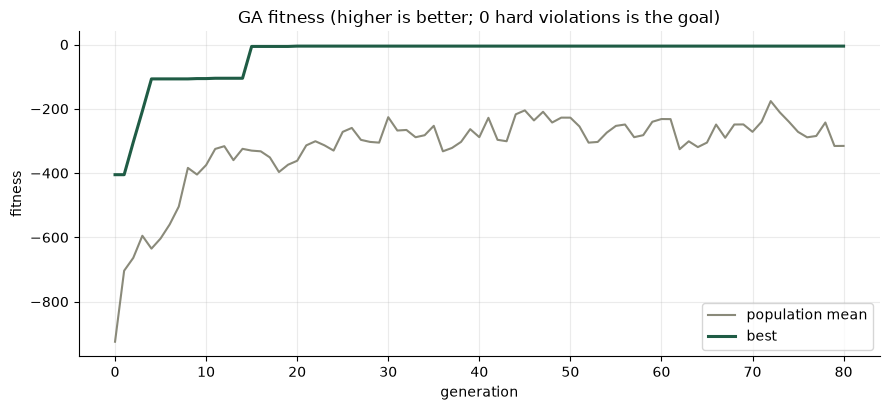

In [ ]:
gens = [row["generation"] for row in history]
fig, ax = plt.subplots()
ax.plot(gens, [row["mean"] for row in history], color="#8a8a7a", label="population mean")
ax.plot(gens, [row["best"] for row in history], color="#1f5c45", linewidth=2.2, label="best")
ax.set_xlabel("generation")
ax.set_ylabel("fitness")
ax.set_title("GA fitness (higher is better; 0 hard violations is the goal)")
ax.legend()
fig.tight_layout()
plt.show()


## 8. Timetable the GA found

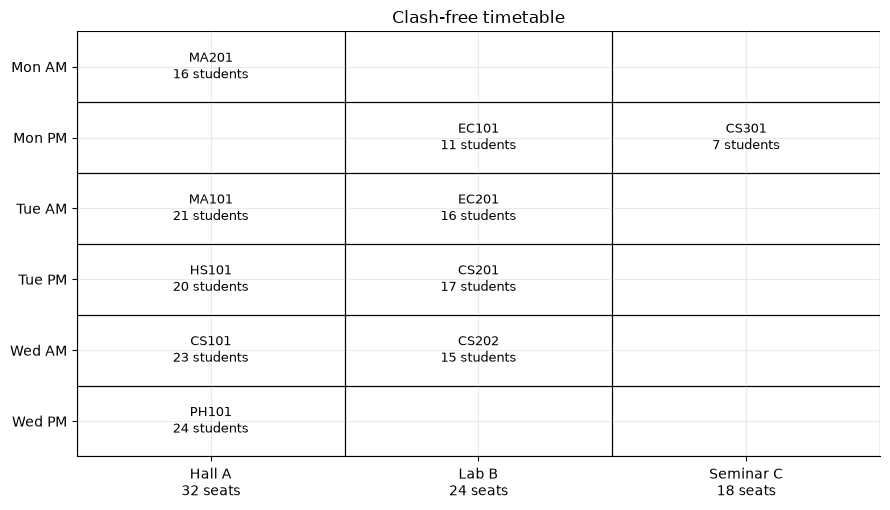

Exam → slot / room
  CS101  Wed AM   Hall A      n=23
  MA101  Tue AM   Hall A      n=21
  PH101  Wed PM   Hall A      n=24
  HS101  Tue PM   Hall A      n=20
  CS201  Tue PM   Lab B       n=17
  CS202  Wed AM   Lab B       n=15
  MA201  Mon AM   Hall A      n=16
  EC101  Mon PM   Lab B       n=11
  EC201  Tue AM   Lab B       n=16
  CS301  Mon PM   Seminar C   n=7


In [ ]:
grid = np.full((N_SLOTS, N_ROOMS), "", dtype=object)
for exam, (slot, room) in enumerate(zip(ga_score["slots"], ga_score["rooms"])):
    label = f"{EXAMS[exam]}\n{HEADCOUNT[exam]} students"
    grid[int(slot), int(room)] = label

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.set_xlim(-0.5, N_ROOMS - 0.5)
ax.set_ylim(N_SLOTS - 0.5, -0.5)
ax.set_xticks(range(N_ROOMS), [f"{name}\n{cap} seats" for name, cap in ROOMS])
ax.set_yticks(range(N_SLOTS), SLOTS)
ax.set_title("Clash-free timetable")
for i in range(N_SLOTS):
    for j in range(N_ROOMS):
        ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, linewidth=0.8))
        if grid[i, j]:
            ax.text(j, i, grid[i, j], ha="center", va="center", fontsize=9)
fig.tight_layout()
plt.show()

print("Exam → slot / room")
for exam, (slot, room) in enumerate(zip(ga_score["slots"], ga_score["rooms"])):
    print(f"  {EXAMS[exam]:<6} {SLOTS[int(slot)]:<8} {ROOM_NAMES[int(room)]:<11} n={HEADCOUNT[exam]}")


## 9. What to write in the report

1. **Problem.** A department must seat 10 papers in 6 slots and 3 rooms without student clashes or overflow.
2. **Soft Computing technique.** Genetic algorithm: integer chromosome, tournament selection, one-point crossover, mutation, elitism.
3. **Why not exact search.** 18 room-slots and clash constraints make this a combinatorial scheduling problem. GA searches the space instead of enumerating it.
4. **Result.** Random assignments stay infeasible. Greedy reduces clashes but still leaves hard violations. The GA reaches 0 hard violations.
5. **Limitation.** This is one department, not a full university. Scale the instance only after the small one is feasible.

No GPU was used. The run is CPU-only and should finish in a few seconds.
